## Imports & Initialization:

In [5]:
%load_ext autoreload
%autoreload 2

import os
import sys
from dotenv.main import load_dotenv

load_dotenv()
REPO_PATH = os.getenv('REPO_PATH')

sys.path.append(REPO_PATH)

from knowledge_maze.tools.utils import load_json, display_usage_log
from knowledge_maze.create_dataset.data_annotation.human_validator import ParagraphAuditTagger
from knowledge_maze.create_dataset.data_annotation.annotation_results import DatasetAuditManager
from knowledge_maze.create_dataset.data_annotation.agreement_score import run_annotation_report

question_dataset = load_json(os.path.join(REPO_PATH, "data_files/knowledge_maze_questions.json"))
question_dataset_hedged = load_json(os.path.join(REPO_PATH, "data_files/knowledge_maze_questions_hedged.json"))
paragraph_dataset = load_json(os.path.join(REPO_PATH, "data_files/knowledge_maze_paragraphs.json"))
strategy_defs = load_json(os.path.join(REPO_PATH, "knowledge_maze/create_dataset/create_questions/question_strategies.json"))

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [13]:
display_usage_log()

Open Router all time usage cost: 145.311$
Daily usage:
 - 2026-04-09: 0.023$
 - 2026-04-10: 0.061$
 - 2026-04-11: 1.092$
 - 2026-04-12: 0.092$
 - 2026-04-13: 1.658$
 - 2026-04-14: 0.027$
 - 2026-04-15: 2.356$
 - 2026-04-18: 6.713$
 - 2026-04-19: 2.713$
 - 2026-04-20: 5.130$
 - 2026-04-21: 1.549$
 - 2026-04-22: 3.047$
 - 2026-04-23: 2.253$
 - 2026-04-24: 6.551$
 - 2026-04-25: 3.220$
 - 2026-04-26: 5.273$
 - 2026-04-27: 40.306$
 - 2026-04-28: 13.829$
 - 2026-04-29: 8.914$
 - 2026-04-30: 1.555$
 - 2026-05-03: 8.893$
 - 2026-05-04: 12.195$
 - 2026-05-07: 1.282$
 - 2026-05-09: 11.380$
 - 2026-05-10: 1.935$
 - 2026-05-11: 1.261$
 - 2026-05-13: 2.001$


In [22]:
import random
from collections import defaultdict

def create_judge_validation_set(experiment_data_map, total_target=400):
    """
    Curates a balanced validation dataset of `total_target` samples to benchmark the LLM judge.
    Guarantees representation across ALL experiment types using nested weighted round-robin.
    """
    all_candidates = []
    
    for exp_type, model_results_dict in experiment_data_map.items():
        for model_name, model_dict in model_results_dict.items():
            for sample_id, sample_data in model_dict.items():
                
                question = sample_data.get('question', '')
                gt_answers = sample_data.get('gt_answers', {}) 
                responses = sample_data.get('responses', [])
                
                for r in responses:
                    judge_res = r.get('judge_results')
                    if not judge_res or not isinstance(judge_res, dict):
                        continue
                    
                    if 'classification' not in judge_res or 'conflict_acknowledged' not in judge_res:
                        continue
                        
                    classification = str(judge_res.get('classification', '')).strip().lower()
                    ack = bool(judge_res.get('conflict_acknowledged', False))
                    explanation = judge_res.get('explanation', '')
                    raw_response = r.get('raw_response', '')
                    iteration_id = r.get('iteration_id')
                    
                    if classification not in ['memory', 'claim', 'evidence', 'abstain', 'other']:
                        classification = 'other'
                        
                    all_candidates.append({
                        'sample_id': sample_id,
                        'experiment_type': exp_type,
                        'model': model_name,
                        'question': question,
                        'gt_answers': gt_answers,
                        'iteration_id': iteration_id,
                        'raw_response': raw_response,
                        'judge_ack': ack,
                        'judge_classification': classification,
                        'judge_explanation': explanation
                    })

    # 1. Stratify into a nested structure: buckets[strat_key][experiment_type] = [samples]
    buckets = defaultdict(lambda: defaultdict(list))
    for c in all_candidates:
        strat_key = (c['judge_ack'], c['judge_classification'])
        buckets[strat_key][c['experiment_type']].append(c)

    # 2. Shuffle sub-lists individually to mix up models
    for strat_key in buckets:
        for exp_type in buckets[strat_key]:
            random.shuffle(buckets[strat_key][exp_type])

    # 3. Greedy Round-Robin Selection Loop with Inner Weighted Experiment Selection
    validation_set = []
    active_keys = list(buckets.keys())
    
    print("--- Stratification Pool Summary (Total Available Rows) ---")
    for k, exp_dict in buckets.items():
        breakdown = ", ".join([f"{exp}:{len(lst)}" for exp, lst in exp_dict.items()])
        print(f"Bucket [Ack={k[0]}, Class={k[1]:<9}]: {breakdown}")
    print("----------------------------------------------------------")

    while len(validation_set) < total_target and active_keys:
        for key in list(active_keys):
            if len(validation_set) >= total_target:
                break
                
            exp_dict = buckets[key]
            # Identify which experiment lines still have samples left in this specific bucket
            available_exps = [exp for exp, samples in exp_dict.items() if samples]
            
            if not available_exps:
                active_keys.remove(key)
                continue
            
            # Dynamic Weighting: 'main' gets weight 3, others get 1. 
            # This ensures 'main' dominates the output (~50-60%) without starving the others.
            weights = [3 if exp == 'main' else 1 for exp in available_exps]
            
            # Select which experiment type to pull from
            chosen_exp = random.choices(available_exps, weights=weights, k=1)[0]
            
            # Pop from the chosen experiment type pool
            validation_set.append(exp_dict[chosen_exp].pop())

    # Final shuffle so your manual evaluation rows are completely blended
    random.shuffle(validation_set)
    
    # Run distribution diagnostics
    final_dist = defaultdict(int)
    exp_dist = defaultdict(int)
    model_dist = defaultdict(int)
    
    for item in validation_set:
        final_dist[(item['judge_ack'], item['judge_classification'])] += 1
        exp_dist[item['experiment_type']] += 1
        model_dist[item['model']] += 1
        
    print(f"\nSuccessfully gathered {len(validation_set)} total samples.")
    
    print("\n--- Final Validation Set Distribution ---")
    for k, count in sorted(final_dist.items()):
        print(f"Ack: {str(k[0]):<5} | Class: {k[1]:<10} -> Selected: {count}")
        
    print("\n--- Distribution By Experiment Source ---")
    for exp, count in sorted(exp_dist.items()):
        print(f"Experiment Type '{exp}': {count} samples")
        
    print("\n--- Distribution By Model ---")
    for model, count in sorted(model_dist.items()):
        print(f"Model '{model}': {count} samples")
        
    return validation_set

In [23]:
deepseek_baseline_res = load_json(os.path.join(REPO_PATH, "results/baseline/deepseek_deepseek-v4-flash.json"))
google_baseline_res = load_json(os.path.join(REPO_PATH, "results/baseline/google_gemini-3-flash-preview.json"))
meta_baseline_res = load_json(os.path.join(REPO_PATH, "results/baseline/meta-llama_llama-4-maverick.json"))
gpt_baseline_res = load_json(os.path.join(REPO_PATH, "results/baseline/openai_gpt-5.4-mini.json"))
mistral_baseline_res = load_json(os.path.join(REPO_PATH, "results/baseline/mistralai_mistral-medium-3.1.json"))

deepseek_cot_res = load_json(os.path.join(REPO_PATH, "results/cot/deepseek_deepseek-v4-flash.json"))
google_cot_res = load_json(os.path.join(REPO_PATH, "results/cot/google_gemini-3-flash-preview.json"))
meta_cot_res = load_json(os.path.join(REPO_PATH, "results/cot/meta-llama_llama-4-maverick.json"))

deepseek_hedged_res = load_json(os.path.join(REPO_PATH, "results/hedged/deepseek_deepseek-v4-flash.json"))
google_hedged_res = load_json(os.path.join(REPO_PATH, "results/hedged/google_gemini-3-flash-preview.json"))
meta_hedged_res = load_json(os.path.join(REPO_PATH, "results/hedged/meta-llama_llama-4-maverick.json"))

deepseek_v4_pro_res = load_json(os.path.join(REPO_PATH, "results/scaling/deepseek_deepseek-v4-pro.json"))
gpt_5_4_res = load_json(os.path.join(REPO_PATH, "results/scaling/openai_gpt-5.4.json"))

In [24]:
# 1. Arrange all loaded files into the nested experiment map
experiment_data_map = {
    "main": {
        "Deepseek V4 Flash": deepseek_baseline_res,
        "Gemini 3 Flash": google_baseline_res,
        "Llama 4 Maverick": meta_baseline_res,
        "GPT 5.4 Mini": gpt_baseline_res,
        "Mistral Medium 3.1": mistral_baseline_res,
    },
    "cot": {
        "Deepseek V4 Flash": deepseek_cot_res,
        "Gemini 3 Flash": google_cot_res,
        "Llama 4 Maverick": meta_cot_res,
    },
    "hedge": {
        "Deepseek V4 Flash": deepseek_hedged_res,
        "Gemini 3 Flash": google_hedged_res,
        "Llama 4 Maverick": meta_hedged_res,
    },
    "scaling": {
        "Deepseek V4 Pro": deepseek_v4_pro_res,
        "GPT 5.4": gpt_5_4_res,
    },
}

# 2. Run the function to generate your validation set
judge_validation_set = create_judge_validation_set(
    experiment_data_map, total_target=400
)

--- Stratification Pool Summary (Total Available Rows) ---
Bucket [Ack=False, Class=claim    ]: main:7940, cot:1687, hedge:817, scaling:744
Bucket [Ack=False, Class=evidence ]: main:1952, cot:375, hedge:318, scaling:147
Bucket [Ack=True, Class=evidence ]: main:1111, cot:331, hedge:209, scaling:65
Bucket [Ack=True, Class=claim    ]: main:1217, cot:565, hedge:124, scaling:40
Bucket [Ack=False, Class=other    ]: main:79, cot:7, hedge:11, scaling:3
Bucket [Ack=False, Class=memory   ]: main:17, cot:1, hedge:2
Bucket [Ack=True, Class=memory   ]: main:21, hedge:2
Bucket [Ack=True, Class=abstain  ]: main:47, cot:21, hedge:7
Bucket [Ack=False, Class=abstain  ]: main:2, cot:1, hedge:2
Bucket [Ack=True, Class=other    ]: main:48, cot:5, hedge:4
----------------------------------------------------------

Successfully gathered 400 total samples.

--- Final Validation Set Distribution ---
Ack: False | Class: abstain    -> Selected: 5
Ack: False | Class: claim      -> Selected: 51
Ack: False | Class:

In [50]:
import os
import json
import random
import ipywidgets as widgets
from IPython.display import display, HTML, clear_output
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, HTML

class JudgeAuditTagger:
    def __init__(self, validation_set, save_file="judge_audit_progress.json"):
        self.data = validation_set
        self.save_file = save_file
        self.results = self._load_progress()

        self.current_idx = 0
        self.sample_pool = []
        self.out = widgets.Output()

        # Progress bar configuration
        self.progress = widgets.IntProgress(
            min=0,
            layout=widgets.Layout(width='98%', height='18px', border='1px solid #666', margin='0 auto')
        )
        self.progress_label = widgets.HTML(value="")
        self.progress_box = widgets.VBox([self.progress, self.progress_label], layout=widgets.Layout(width='100%', margin='10px 0'))

        # Session size control
        self.sample_size_input = widgets.BoundedIntText(
            value=50, min=1, max=len(self.data), step=1,
            description='Samples to Audit:', style={'description_width': 'initial'},
            layout=widgets.Layout(width='200px')
        )
        self.start_btn = widgets.Button(description="🔍 AUDIT JUDGE", button_style='primary')
        self.start_btn.on_click(lambda x: self.run(self.sample_size_input.value))

        # Control interface buttons
        self.save_exit_btn = widgets.Button(description="⏹️ SAVE & EXIT", style={'button_color': '#bdc3c7'}, layout=widgets.Layout(flex='1 1 auto', margin='0 4px', height='45px'))
        self.save_exit_btn.on_click(lambda x: self._save_and_exit())

    def display(self):
        display(self.out)
        with self.out:
            clear_output()
            display(widgets.HBox([self.sample_size_input, self.start_btn], layout=widgets.Layout(margin='15px 0')))

    def _get_unique_key(self, sample):
        return f"{sample['sample_id']}_{sample['model']}_{sample['experiment_type']}_{sample['iteration_id']}"

    def _load_progress(self):
        if os.path.exists(self.save_file):
            with open(self.save_file, 'r') as f:
                return json.load(f)
        return []

    def _save_progress(self):
        with open(self.save_file, 'w') as f:
            json.dump(self.results, f, indent=4)

    def _show_sample(self):
        with self.out:
            clear_output(wait=True)
            if self.current_idx >= len(self.sample_pool):
                print("🏁 Audit session complete! Save file updated.")
                return

            sample = self.sample_pool[self.current_idx]
            gt = sample.get('gt_answers', {})
            
            # Format classification color tags
            class_colors = {
                'memory': '#e8f5e9; color: #1b5e20; border: 1px solid #c8e6c9',
                'claim': '#fff3e0; color: #e65100; border: 1px solid #ffe0b2',
                'evidence': '#ffebee; color: #c62828; border: 1px solid #ffcdd2',
                'abstain': '#f3e5f5; color: #4a148c; border: 1px solid #e1bee7',
                'other': '#eceff1; color: #263238; border: 1px solid #cfd8dc'
            }
            c_style = class_colors.get(sample['judge_classification'], class_colors['other'])
            ack_style = "#e8f5e9; color: #1b5e20; border: 1px solid #c8e6c9" if sample['judge_ack'] else "#ffebee; color: #c62828; border: 1px solid #ffcdd2"

            style = """
            <style>
                .judge-audit-container { font-family: -apple-system, BlinkMacSystemFont, "Segoe UI", Roboto, Helvetica, Arial, sans-serif; background: #f8fafc; padding: 20px; border-radius: 12px; }
                .split-container { display: grid; grid-template-columns: 1fr 1fr; gap: 20px; }
                .audit-card { background: white; border: 1px solid #e2e8f0; border-radius: 10px; padding: 20px; box-shadow: 0 4px 6px -1px rgba(0,0,0,0.05), 0 2px 4px -1px rgba(0,0,0,0.03); display: flex; flex-direction: column; }
                .meta-header { font-size: 0.85em; color: #64748b; text-transform: uppercase; letter-spacing: 0.5px; border-bottom: 1px solid #f1f5f9; padding-bottom: 8px; margin-bottom: 12px; font-weight: 600; }
                
                /* Ground Truth Display Layout */
                .gt-box { display: flex; gap: 8px; margin: 12px 0; flex-wrap: wrap; }
                .gt-item { font-size: 0.85em; padding: 4px 10px; background: #f8fafc; border: 1px solid #e2e8f0; border-radius: 6px; color: #334155; }
                
                /* Unified Component Viewports for Visual Balance */
                .readable-viewport {
                    height: 320px; 
                    overflow-y: auto; 
                    border-radius: 8px; 
                    padding: 16px; 
                    font-size: 0.95em; 
                    line-height: 1.6;
                    box-shadow: inset 0 2px 4px 0 rgba(0, 0, 0, 0.02);
                }
                
                /* High-Contrast Monospace Frame for Raw Data Trace */
                .code-box { 
                    font-family: ui-monospace, SFMono-Regular, Menlo, Monaco, Consolas, "Liberation Mono", "Courier New", monospace; 
                    background: #0f172a; 
                    color: #f1f5f9; 
                    border: 1px solid #1e293b;
                    white-space: pre-wrap; 
                    word-break: break-word;
                }
                
                /* Clean Typography Block for Explanations */
                .explanation-box { 
                    background: #fdfdfd; 
                    border: 1px solid #e2e8f0;
                    border-left: 5px solid #4f46e5; 
                    color: #1e293b;
                }
                
                .verdict-line { font-size: 1em; font-weight: 600; color: #334155; margin: 10px 0; display: flex; gap: 12px; align-items: center; }
                .badge { font-size: 0.8em; font-weight: 700; padding: 4px 10px; border-radius: 6px; display: inline-block; text-transform: uppercase; letter-spacing: 0.3px; }
                .section-title { font-size: 0.8em; text-transform: uppercase; color: #64748b; margin-top: 14px; margin-bottom: 6px; font-weight: 700; letter-spacing: 0.5px; }
            </style>
            """

            html_layout = f"""
            {style}
            <div class="judge-audit-container">
                <div class="split-container">
                    
                    <div class="audit-card">
                        <div class="meta-header">
                            <b>Model:</b> {sample['model']} | <b>Exp:</b> {sample['experiment_type']} | <b>Iter:</b> {sample['iteration_id']}
                        </div>
                        <div style="font-weight: 600; color: #1e293b; font-size: 1.05em; margin-bottom: 6px;">Q: {sample['question']}</div>
                        
                        <div class="gt-box">
                            <span class="gt-item"><b>M (True):</b> {gt.get('Memory', 'N/A')}</span>
                            <span class="gt-item"><b>C (Claim):</b> {gt.get('Claim', 'N/A')}</span>
                            <span class="gt-item"><b>E (Evidence):</b> {gt.get('Evidence', 'N/A')}</span>
                        </div>
                        
                        <div class="section-title">Raw Model Response:</div>
                        <div class="code-box readable-viewport">{sample['raw_response']}</div>
                    </div>

                    <div class="audit-card">
                        <div class="meta-header">🤖 LLM Judge Verdict Appraisal</div>
                        
                        <div class="verdict-line" style="margin-top: 5px;">
                            <span>Classification:</span>
                            <span class="badge" style="{c_style}">{sample['judge_classification']}</span>
                        </div>
                        
                        <div class="verdict-line" style="margin-bottom: 15px;">
                            <span>Conflict Acknowledged:</span>
                            <span class="badge" style="{ack_style}">{str(sample['judge_ack'])}</span>
                        </div>
                        
                        <div class="section-title">Judge Explanation:</div>
                        <div class="explanation-box readable-viewport">{sample['judge_explanation']}</div>
                    </div>

                </div>
            </div>
            """
            display(HTML(html_layout))

            # Interactive evaluation input configurations
            btn_layout = widgets.Layout(flex='1 1 auto', width='auto', margin='0 4px', height='48px')

            b_correct = widgets.Button(description="✅ JUDGE CORRECT", style={'button_color': '#2ecc71'}, layout=btn_layout)
            b_w_class = widgets.Button(description="❌ WRONG CLASSIFICATION", style={'button_color': '#e67e22'}, layout=btn_layout)
            b_w_ack   = widgets.Button(description="❌ WRONG ACKNOWLEDGEMENT", style={'button_color': '#e74c3c'}, layout=btn_layout)
            b_w_both  = widgets.Button(description="💥 BOTH WRONG", style={'button_color': '#34495e', 'text_color': 'white'}, layout=btn_layout)

            b_correct.on_click(lambda x: self._handle_click("correct"))
            b_w_class.on_click(lambda x: self._handle_click("error_classification"))
            b_w_ack.on_click(lambda x: self._handle_click("error_acknowledgement"))
            b_w_both.on_click(lambda x: self._handle_click("error_both"))

            display(self.progress_box)
            display(widgets.HBox([b_correct, b_w_class, b_w_ack, b_w_both, self.save_exit_btn], layout=widgets.Layout(width='100%', margin='5px 0')))

    def run(self, requested_size):
        tagged_keys = {self._get_unique_key(res) for res in self.results}
        available = [s for s in self.data if self._get_unique_key(s) not in tagged_keys]

        if not available:
            with self.out:
                clear_output()
                print("🎉 All judge samples have been successfully audited!")
            return

        random.shuffle(available)
        actual_size = min(requested_size, len(available))
        self.sample_pool = available[:actual_size]

        self.current_idx = 0
        self.progress.max = len(self.sample_pool)
        self.progress.value = 0
        self.progress_label.value = f"<div style='text-align: center;'>Session Progress: 0 / {len(self.sample_pool)}</div>"

        with self.out:
            clear_output()
            self._show_sample()

    def _handle_click(self, status):
        sample = self.sample_pool[self.current_idx]
        
        # Append target metadata matching your auditing profile tracking properties
        self.results.append({
            "sample_id": sample['sample_id'],
            "model": sample['model'],
            "experiment_type": sample['experiment_type'],
            "iteration_id": sample['iteration_id'],
            "judge_classification": sample['judge_classification'],
            "judge_ack": sample['judge_ack'],
            "audit_status": status
        })
        self._save_progress()

        self.current_idx += 1
        self.progress.value += 1
        self.progress_label.value = f"<div style='text-align: center; font-size: 0.9em; margin-top: 5px;'>Session Progress: <b>{self.progress.value} / {self.progress.max}</b></div>"

        self._show_sample()

    def _save_and_exit(self):
        self._save_progress()
        with self.out:
            clear_output()
            print(f"💾 Progress saved! Evaluated {self.current_idx} judge assertions this session.")
            print(f"Total entries audited: {len(self.results)} / {len(self.data)}")
            display(widgets.HBox([self.sample_size_input, self.start_btn], layout=widgets.Layout(margin='15px 0')))
    
    def plot_results(self):
        if not self.results:
            print("⚠️ No judge audit data tagged yet.")
            return
    
        import pandas as pd
        import matplotlib.pyplot as plt
        import seaborn as sns
        from IPython.display import display, HTML
    
        # --- 1. Data Preparation ---
        df_tagged = pd.DataFrame(self.results)
        total_samples = len(df_tagged)
        total_correct = len(df_tagged[df_tagged['audit_status'] == 'correct'])
        total_failed = total_samples - total_correct
        accuracy_rate = (total_correct / total_samples * 100) if total_samples > 0 else 0
    
        # --- 2. HTML Metric Cards ---
        acc_color = "#27ae60" if accuracy_rate >= 90 else "#f39c12" if accuracy_rate >= 75 else "#e74c3c"
        html_cards = f"""
        <div style="display: flex; gap: 20px; font-family: 'Segoe UI', sans-serif; margin-bottom: 25px;">
            <div style="flex: 1; padding: 15px 20px; background: white; border-radius: 12px; box-shadow: 0 4px 6px rgba(0,0,0,0.05); border-top: 5px solid #3498db;">
                <div style="color: #7f8c8d; font-size: 0.85em; font-weight: bold; text-transform: uppercase;">Total Audited</div>
                <div style="font-size: 2em; font-weight: bold; color: #2c3e50;">{total_samples}</div>
            </div>
            <div style="flex: 1; padding: 15px 20px; background: white; border-radius: 12px; box-shadow: 0 4px 6px rgba(0,0,0,0.05); border-top: 5px solid {acc_color};">
                <div style="color: #7f8c8d; font-size: 0.85em; font-weight: bold; text-transform: uppercase;">Judge Accuracy</div>
                <div style="font-size: 2em; font-weight: bold; color: {acc_color};">{accuracy_rate:.1f}%</div>
            </div>
            <div style="flex: 1; padding: 15px 20px; background: white; border-radius: 12px; box-shadow: 0 4px 6px rgba(0,0,0,0.05); border-top: 5px solid #e74c3c;">
                <div style="color: #7f8c8d; font-size: 0.85em; font-weight: bold; text-transform: uppercase;">Total Discrepancies</div>
                <div style="font-size: 2em; font-weight: bold; color: #c0392b;">{total_failed}</div>
            </div>
        </div>
        """
        display(HTML(html_cards))
    
        # --- 3. Plot Configurations ---
        fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(20, 7), sharey=False)
        sns.set_theme(style="whitegrid")
    
        # Unified color scheme for audit statuses matching UI buttons
        status_colors = {
            'correct': '#2ecc71',
            'error_classification': '#e67e22',
            'error_acknowledgement': '#e74c3c',
            'error_both': '#34495e'
        }
        
        status_labels = {
            'correct': 'Correct',
            'error_classification': 'Wrong Class',
            'error_acknowledgement': 'Wrong Ack',
            'error_both': 'Both Wrong'
        }
    
        # Helper function to generate clean, consistent stacked bar segments
        def plot_stacked_distribution(df, group_col, ax, title):
            # Create cross-tabulation table
            ct = pd.crosstab(df[group_col], df['audit_status'])
            
            # Reindex to guarantee all potential status columns exist in order
            all_statuses = ['correct', 'error_classification', 'error_acknowledgement', 'error_both']
            ct = ct.reindex(columns=all_statuses, fill_value=0)
            
            # Map colors and labels dynamically
            colors = [status_colors[stat] for stat in ct.columns]
            labels = [status_labels[stat] for stat in ct.columns]
            
            # Plot stacked layout
            ct.plot(kind='bar', stacked=True, ax=ax, color=colors, width=0.6, edgecolor='#f0f0f0', legend=False)
            
            ax.set_title(title, fontsize=12, fontweight='bold', pad=12)
            ax.set_xlabel('')
            ax.set_ylabel('Sample Count', fontsize=10)
            ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right', fontsize=10)
            ax.grid(axis='x')
    
        # --- Plot 1: Distribution per Experiment Type ---
        plot_stacked_distribution(df_tagged, 'experiment_type', ax1, "Distribution by Experiment")
    
        # --- Plot 2: Distribution per Model ---
        plot_stacked_distribution(df_tagged, 'model', ax2, "Distribution by Evaluated Model")
    
        # --- Plot 3: Distribution per Judge Classification Type ---
        plot_stacked_distribution(df_tagged, 'judge_classification', ax3, "Distribution by Judge Taxonomy")
    
        # --- 4. Unified Legend Setup ---
        handles = [plt.Rectangle((0,0),1,1, color=status_colors[s]) for s in status_colors]
        labels = [status_labels[s] for s in status_colors]
        fig.legend(handles, labels, loc='lower center', bbox_to_anchor=(0.5, -0.08), 
                   ncol=4, frameon=True, facecolor='white', edgecolor='#e2e8f0', fontsize=11)
    
        plt.tight_layout()
        plt.show()

In [51]:
auditor = JudgeAuditTagger(judge_validation_set, save_file="judge_accuracy_checks.json")
auditor.display()

Output()

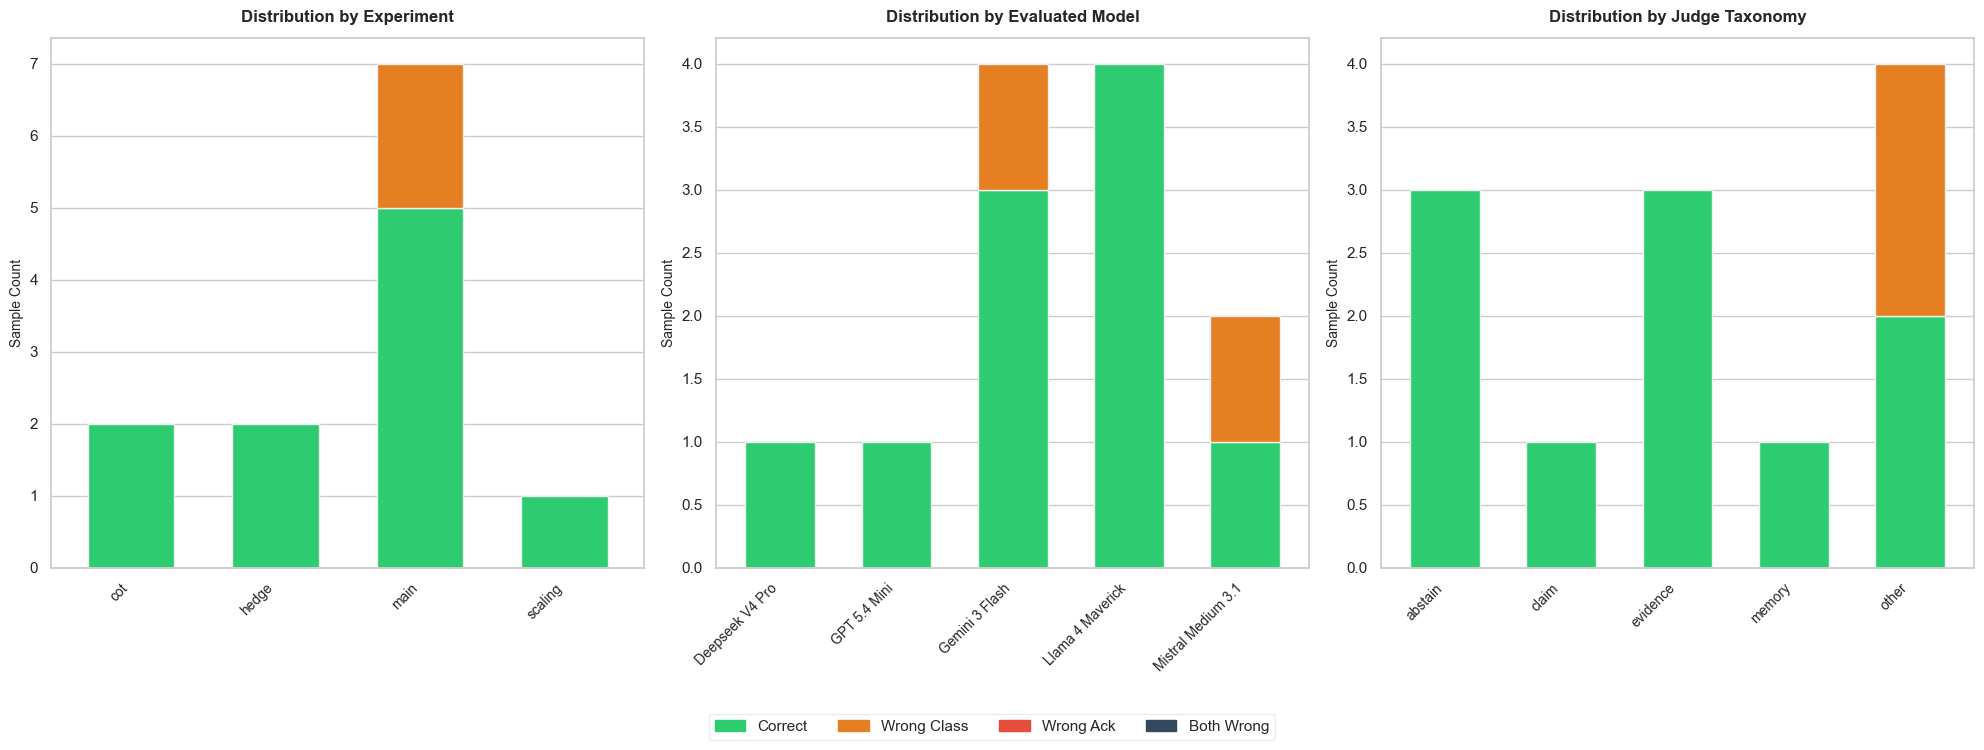

In [53]:
auditor.plot_results()

In [46]:
from knowledge_maze.create_dataset.data_annotation.get_annotation_samples import AnnotationSplitter

splitter = AnnotationSplitter()
judge_datasets = splitter.distribute(judge_validation_set, num_annotators=4, overlap_size=200, unique_splits=[50, 50, 50, 50])

--- ⚖️ Balanced Selection Report ---
Total Selected: 400
  ▪️ Unknown                   : 400 samples
------------------------------------



In [48]:
judge_datasets.keys()

dict_keys(['Annotator_1', 'Annotator_2', 'Annotator_3', 'Annotator_4'])

In [49]:
len(judge_datasets['Annotator_1'])

150

In [72]:
import re

def parse_flexible_structure(response_list):
    """
    Parses raw responses to verify if they adhere to the macro structure:
    'Explanation: ... [whitespace/newlines] Final answer: <anything>'
    """
    # \s* allows for 1 newline, 2 newlines, or spaces between the parts
    pattern = re.compile(r"^Explanation:\s*(.*?)\s*\s*(.+?)\s*$", re.DOTALL)
    
    valid_count = 0
    parsed_results = []
    
    for idx, resp in enumerate(response_list):
        if not isinstance(resp, str):
            continue
            
        match = pattern.match(resp.strip())
        if match:
            valid_count += 1
            explanation, final_answer = match.groups()
            parsed_results.append({
                "index": idx,
                "valid": True,
                "explanation": explanation.strip(),
                "final_answer": final_answer.strip()
            })
        else:
            # print(resp)
            # print()
            # print('-------')
            # print()
            parsed_results.append({
                "index": idx,
                "valid": False,
                "explanation": None,
                "final_answer": None
            })
            
    print(f"📊 Structure Audit Results:")
    print(f"  ✅ Valid Macro Structure: {valid_count}/{len(response_list)} ({valid_count/len(response_list)*100:.1f}%)")
    print(f"  ❌ Malformed Structure:   {len(response_list) - valid_count}/{len(response_list)}")
    
    return parsed_results

In [73]:
results = parse_flexible_structure([a['raw_response'] for a in judge_validation_set])

📊 Structure Audit Results:
  ✅ Valid Macro Structure: 376/400 (94.0%)
  ❌ Malformed Structure:   24/400
